# Thumbnail Data Collection Pipeline
**Project:** Annotation-Free Video Thumbnail Consistency Scoring  
**Stage:** 0 — Data Collection & Formatting  

All bugs from v1 fixed:
- Timestamp offset corrected (`float(i)` not `float(i+1)`)
- `aligned_pairs.json` now saved to disk
- Frame filtering implemented (blur + brightness + near-duplicate)
- Skip logic added to every processing cell
- yt-dlp JS runtime warning fixed
- Validation cell added at end
- Google Drive mount added

# 1. Install & Imports

In [1]:
!pip install -q openai-whisper yt-dlp ffmpeg-python opencv-python imagehash Pillow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 19.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 182.3/182.3 kB 21.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 104.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 34.4 MB/s eta 0:00:00


In [2]:
import os
import json
import subprocess
import numpy as np
import cv2
import imagehash
import whisper
import torch
import random
import matplotlib.pyplot as plt

from PIL import Image
from datetime import datetime

# ── CONFIG ──────────────────────────────────────────────
# Change RAW_DIR to your Drive path when working with team:
# RAW_DIR = "/content/drive/MyDrive/thumbnail_project/raw"
RAW_DIR = "raw"

WHISPER_MODEL   = "small"   # use "medium" for final dataset
FRAME_FPS       = 1
BLUR_THRESHOLD  = 100       # Laplacian variance — below = blurry
DARK_THRESHOLD  = 30        # mean pixel brightness — below = too dark
DUP_THRESHOLD   = 0.95      # perceptual hash similarity — above = duplicate
ANNOTATOR_NAME  = "Zakaria"  # ← change this

os.makedirs(RAW_DIR, exist_ok=True)
print(f"GPU available: {torch.cuda.is_available()}")
print(f"RAW_DIR: {os.path.abspath(RAW_DIR)}")

GPU available: True
RAW_DIR: /content/raw


## 1b. Google Drive Mount (team use)
Run this cell only when using shared Drive storage.  
Skip it if working locally.

In [ ]:
# Uncomment to mount Drive
# from google.colab import drive
# drive.mount('/content/drive')
# RAW_DIR = "/content/drive/MyDrive/thumbnail_project/raw"
# os.makedirs(RAW_DIR, exist_ok=True)
# print("Drive mounted. RAW_DIR:", RAW_DIR)

Mounted at /content/drive
Drive mounted. RAW_DIR: /content/drive/MyDrive/thumbnail_project/raw


In [26]:
shutil.copytree(
    "/content/raw",
    "/content/drive/MyDrive/thumbnail_project/raw",
    dirs_exist_ok=True
)


'/content/drive/MyDrive/thumbnail_project/raw'

In [ ]:
urls = [
]

# 2. Video Download
Add your YouTube URLs to the `urls` list.  
Each video is saved to `raw/{video_id}/`.

In [ ]:
failed = []

for url in urls:
    # Extract video ID from URL to check if already downloaded
    try:
        result = subprocess.run(
            ["yt-dlp", "--get-id", url],
            capture_output=True, text=True, timeout=30
        )
        video_id = result.stdout.strip()
    except Exception:
        video_id = None

    # ── SKIP LOGIC: skip if folder already exists with video ──
    if video_id:
        folder_path = os.path.join(RAW_DIR, video_id)
        video_file  = os.path.join(folder_path, "video.mp4")
        if os.path.exists(video_file):
            print(f"Skipping {video_id} — already downloaded")
            continue

    print(f"Downloading: {url}")
    try:
        os.system(
            f'yt-dlp '
            f'--format "bestvideo[ext=mp4]+bestaudio[ext=m4a]/best[ext=mp4]/mp4" '
            f'--merge-output-format mp4 '
            f'--write-info-json '
            f'--write-thumbnail '
            f'--convert-thumbnails jpg '
            f'--extractor-args "youtube:player_client=android" '
            f'--output "{RAW_DIR}/%(id)s/%(id)s.%(ext)s" '
            f'"{url}"'
        )
        print(f"Done: {url}\n")
    except Exception as e:
        print(f"Error with {url}: {e}\n")
        failed.append(url)

if failed:
    print(f"\nFailed URLs: {failed}")
else:
    print("\nAll downloads complete.")


Downloading: https://www.youtube.com/watch?v=oeqPrUmVz-o
Done: https://www.youtube.com/watch?v=oeqPrUmVz-o

Downloading: https://www.youtube.com/watch?v=VnwNR5qR9ow
Done: https://www.youtube.com/watch?v=VnwNR5qR9ow

Downloading: https://www.youtube.com/watch?v=zwUIRMTO4N4
Done: https://www.youtube.com/watch?v=zwUIRMTO4N4

Downloading: https://www.youtube.com/watch?v=CG1Yzk_F0P8
Done: https://www.youtube.com/watch?v=CG1Yzk_F0P8

Downloading: https://www.youtube.com/watch?v=NqFi90p38N8
Done: https://www.youtube.com/watch?v=NqFi90p38N8

Downloading: https://www.youtube.com/watch?v=Fpf-MvnxpWs
Done: https://www.youtube.com/watch?v=Fpf-MvnxpWs

Downloading: https://www.youtube.com/watch?v=MDcnGfznHV8
Done: https://www.youtube.com/watch?v=MDcnGfznHV8

Downloading: https://www.youtube.com/watch?v=928aRhhPP8I
Done: https://www.youtube.com/watch?v=928aRhhPP8I

Downloading: https://www.youtube.com/watch?v=hyK8fqUjF2U
Done: https://www.youtube.com/watch?v=hyK8fqUjF2U

Downloading: https://www.you

In [6]:
# Rename yt-dlp output files to clean standard names
for folder in os.listdir(RAW_DIR):
    folder_path = os.path.join(RAW_DIR, folder)
    if not os.path.isdir(folder_path):
        continue

    for file in os.listdir(folder_path):
        old_path = os.path.join(folder_path, file)

        if file.endswith(".mp4") and file != "video.mp4":
            os.rename(old_path, os.path.join(folder_path, "video.mp4"))

        elif file.endswith(".info.json") and file != "info.json":
            os.rename(old_path, os.path.join(folder_path, "info.json"))

        elif file.endswith(".jpg") and file != "thumbnail.jpg":
            # Only rename if it looks like the thumbnail (not a frame)
            if "frame" not in file:
                os.rename(old_path, os.path.join(folder_path, "thumbnail.jpg"))

print("File renaming complete.")


File renaming complete.


# 3. Metadata Extraction

In [7]:
for folder in os.listdir(RAW_DIR):
    folder_path = os.path.join(RAW_DIR, folder)
    if not os.path.isdir(folder_path):
        continue

    meta_path = os.path.join(folder_path, "meta.json")

    # ── SKIP LOGIC ──
    if os.path.exists(meta_path):
        print(f"Skipping {folder} — meta.json exists")
        continue

    info_path = os.path.join(folder_path, "info.json")
    if not os.path.exists(info_path):
        print(f"Skipping {folder} — no info.json found")
        continue

    with open(info_path, "r") as f:
        data = json.load(f)

    title       = data.get("title", "")
    description = data.get("description", "")

    with open(os.path.join(folder_path, "title.txt"), "w") as f:
        f.write(title)

    with open(os.path.join(folder_path, "description.txt"), "w") as f:
        f.write(description)

    meta = {
        "video_id":         data.get("id"),
        "title":            title,
        "duration_seconds": data.get("duration"),
        "upload_date":      data.get("upload_date"),
        "channel_id":       data.get("channel_id"),
        "channel_name":     data.get("channel"),
        "category":         data.get("categories"),
        "tags":             data.get("tags"),
        "view_count":       data.get("view_count"),
        "like_count":       data.get("like_count"),
        "language":         data.get("language"),
        "thumbnail_url":    data.get("thumbnail"),
    }

    with open(meta_path, "w") as f:
        json.dump(meta, f, indent=2)

    print(f"Processed metadata: {folder}")

Processed metadata: swadfg2DtYo
Processed metadata: 0nUeIjPrsCM
Processed metadata: jPvt-ap8Jbc
Processed metadata: zwUIRMTO4N4
Processed metadata: hyK8fqUjF2U
Processed metadata: NqFi90p38N8
Processed metadata: _6Nu1p1HYjY
Processed metadata: s_23eRHK2Qw
Processed metadata: UTl92LSCkZM
Processed metadata: CG1Yzk_F0P8
Processed metadata: MDcnGfznHV8
Processed metadata: 928aRhhPP8I
Processed metadata: q0ZslYBBU0U
Processed metadata: PHwEIY-BeIM
Processed metadata: suwYQxNxJ-g
Processed metadata: oeqPrUmVz-o
Processed metadata: H8J6R8wVhRU
Processed metadata: VnwNR5qR9ow
Processed metadata: YpNcnM0FkTM
Processed metadata: lumimB_aa7M
Processed metadata: Ba6-6KmB3CQ
Processed metadata: Fpf-MvnxpWs
Processed metadata: iDzlbA3xIJ8


# 4. Frame Extraction

In [8]:
for folder in os.listdir(RAW_DIR):
    folder_path = os.path.join(RAW_DIR, folder)
    if not os.path.isdir(folder_path):
        continue

    video_path  = os.path.join(folder_path, "video.mp4")
    frames_path = os.path.join(folder_path, "frames")

    # ── SKIP LOGIC ──
    if os.path.exists(frames_path) and len(os.listdir(frames_path)) > 0:
        print(f"Skipping {folder} — frames already extracted")
        continue

    if not os.path.exists(video_path):
        print(f"Skipping {folder} — no video.mp4")
        continue

    os.makedirs(frames_path, exist_ok=True)
    print(f"Extracting frames: {folder}")
    os.system(
        f'ffmpeg -i "{video_path}" -vf fps={FRAME_FPS} -q:v 2 '
        f'"{frames_path}/frame_%05d.jpg" -loglevel error'
    )
    n = len(os.listdir(frames_path))
    print(f"Done — {n} frames extracted\n")


Extracting frames: swadfg2DtYo
Done — 838 frames extracted

Extracting frames: 0nUeIjPrsCM
Done — 774 frames extracted

Extracting frames: jPvt-ap8Jbc
Done — 966 frames extracted

Extracting frames: zwUIRMTO4N4
Done — 460 frames extracted

Extracting frames: hyK8fqUjF2U
Done — 237 frames extracted

Extracting frames: NqFi90p38N8
Done — 611 frames extracted

Extracting frames: _6Nu1p1HYjY
Done — 655 frames extracted

Extracting frames: s_23eRHK2Qw
Done — 833 frames extracted

Extracting frames: UTl92LSCkZM
Done — 370 frames extracted

Extracting frames: CG1Yzk_F0P8
Done — 611 frames extracted

Extracting frames: MDcnGfznHV8
Done — 925 frames extracted

Extracting frames: 928aRhhPP8I
Done — 783 frames extracted

Extracting frames: q0ZslYBBU0U
Done — 326 frames extracted

Extracting frames: PHwEIY-BeIM
Done — 771 frames extracted

Extracting frames: suwYQxNxJ-g
Done — 610 frames extracted

Extracting frames: oeqPrUmVz-o
Done — 315 frames extracted

Extracting frames: H8J6R8wVhRU
Done — 81

## 4.1 Frame Index

In [ ]:
# BUG FIX: timestamp_sec uses float(i) not float(i+1)
# frame_00001.jpg is at second 0, not second 1
for folder in os.listdir(RAW_DIR):
    folder_path = os.path.join(RAW_DIR, folder)
    if not os.path.isdir(folder_path):
        continue

    frames_path      = os.path.join(folder_path, "frames")
    index_path       = os.path.join(folder_path, "frames_index.json")

    # ── SKIP LOGIC ──
    if os.path.exists(index_path):
        print(f"Skipping {folder} — frames_index.json exists")
        continue

    if not os.path.exists(frames_path):
        continue

    frames = sorted([f for f in os.listdir(frames_path) if f.endswith(".jpg")])

    index = [
        {"frame_file": frame, "timestamp_sec": float(i)}   # FIXED: float(i) not float(i+1)
        for i, frame in enumerate(frames)
    ]

    with open(index_path, "w") as f:
        json.dump(index, f, indent=2)

    print(f"Frame index created: {folder}  ({len(frames)} frames)")

Frame index created: swadfg2DtYo  (838 frames)
Frame index created: 0nUeIjPrsCM  (774 frames)
Frame index created: jPvt-ap8Jbc  (966 frames)
Frame index created: zwUIRMTO4N4  (460 frames)
Frame index created: hyK8fqUjF2U  (237 frames)
Frame index created: NqFi90p38N8  (611 frames)
Frame index created: _6Nu1p1HYjY  (655 frames)
Frame index created: s_23eRHK2Qw  (833 frames)
Frame index created: UTl92LSCkZM  (370 frames)
Frame index created: CG1Yzk_F0P8  (611 frames)
Frame index created: MDcnGfznHV8  (925 frames)
Frame index created: 928aRhhPP8I  (783 frames)
Frame index created: q0ZslYBBU0U  (326 frames)
Frame index created: PHwEIY-BeIM  (771 frames)
Frame index created: suwYQxNxJ-g  (610 frames)
Frame index created: oeqPrUmVz-o  (315 frames)
Frame index created: H8J6R8wVhRU  (818 frames)
Frame index created: VnwNR5qR9ow  (254 frames)
Frame index created: YpNcnM0FkTM  (557 frames)
Frame index created: lumimB_aa7M  (430 frames)
Frame index created: Ba6-6KmB3CQ  (510 frames)
Frame index c

## 4.2 Frame Filtering
Remove blurry, dark, and near-duplicate frames.  
Discarded frames are logged to `frames_discarded.json` — not deleted permanently.

In [ ]:
def laplacian_variance(image_path):
    """Higher = sharper. Below BLUR_THRESHOLD = blurry."""
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return 0
    return float(cv2.Laplacian(img, cv2.CV_64F).var())

def mean_brightness(image_path):
    """Mean pixel brightness [0-255]. Below DARK_THRESHOLD = too dark."""
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return 0
    return float(np.mean(img))

def phash(image_path):
    """Perceptual hash for near-duplicate detection."""
    try:
        return imagehash.phash(Image.open(image_path))
    except Exception:
        return None

for folder in os.listdir(RAW_DIR):
    folder_path = os.path.join(RAW_DIR, folder)
    if not os.path.isdir(folder_path):
        continue

    frames_path   = os.path.join(folder_path, "frames")
    index_path    = os.path.join(folder_path, "frames_index.json")
    discard_path  = os.path.join(folder_path, "frames_discarded.json")

    # ── SKIP LOGIC ──
    if os.path.exists(discard_path):
        print(f"Skipping {folder} — filtering already done")
        continue

    if not os.path.exists(index_path):
        print(f"Skipping {folder} — no frames_index.json")
        continue

    with open(index_path) as f:
        index = json.load(f)

    kept      = []
    discarded = []
    prev_hash = None

    for item in index:
        frame_path = os.path.join(frames_path, item["frame_file"])

        if not os.path.exists(frame_path):
            discarded.append({**item, "reason": "file_missing"})
            continue

        blur = laplacian_variance(frame_path)
        brightness = mean_brightness(frame_path)
        h = phash(frame_path)

        # Check blur
        if blur < BLUR_THRESHOLD:
            discarded.append({**item, "reason": "blurry", "blur_score": blur})
            continue

        # Check darkness
        if brightness < DARK_THRESHOLD:
            discarded.append({**item, "reason": "dark", "brightness": brightness})
            continue

        # Check near-duplicate vs previous kept frame
        if prev_hash is not None and h is not None:
            similarity = 1 - (h - prev_hash) / len(h.hash) ** 2
            if similarity > DUP_THRESHOLD:
                discarded.append({**item, "reason": "duplicate", "similarity": similarity})
                continue

        prev_hash = h
        kept.append(item)

    # Overwrite frames_index.json with only kept frames
    with open(index_path, "w") as f:
        json.dump(kept, f, indent=2)

    with open(discard_path, "w") as f:
        json.dump(discarded, f, indent=2)

    print(f"{folder}: kept {len(kept)}, discarded {len(discarded)}")

swadfg2DtYo: kept 758, discarded 80
0nUeIjPrsCM: kept 606, discarded 168
jPvt-ap8Jbc: kept 447, discarded 519
zwUIRMTO4N4: kept 230, discarded 230
hyK8fqUjF2U: kept 163, discarded 74
NqFi90p38N8: kept 398, discarded 213
_6Nu1p1HYjY: kept 579, discarded 76
s_23eRHK2Qw: kept 804, discarded 29
UTl92LSCkZM: kept 235, discarded 135
CG1Yzk_F0P8: kept 324, discarded 287
MDcnGfznHV8: kept 820, discarded 105
928aRhhPP8I: kept 634, discarded 149
q0ZslYBBU0U: kept 283, discarded 43
PHwEIY-BeIM: kept 665, discarded 106
suwYQxNxJ-g: kept 576, discarded 34
oeqPrUmVz-o: kept 243, discarded 72
H8J6R8wVhRU: kept 787, discarded 31
VnwNR5qR9ow: kept 127, discarded 127
YpNcnM0FkTM: kept 491, discarded 66
lumimB_aa7M: kept 182, discarded 248
Ba6-6KmB3CQ: kept 394, discarded 116
Fpf-MvnxpWs: kept 60, discarded 50
iDzlbA3xIJ8: kept 232, discarded 84


# 5. Audio Extraction

In [ ]:
for folder in os.listdir(RAW_DIR):
    folder_path = os.path.join(RAW_DIR, folder)
    if not os.path.isdir(folder_path):
        continue

    video_path = os.path.join(folder_path, "video.mp4")
    audio_path = os.path.join(folder_path, "audio.wav")

    # ── SKIP LOGIC ──
    if os.path.exists(audio_path):
        print(f"Skipping {folder} — audio.wav exists")
        continue

    if not os.path.exists(video_path):
        print(f"Skipping {folder} — no video.mp4")
        continue

    print(f"Extracting audio: {folder}")
    os.system(
        f'ffmpeg -i "{video_path}" -vn -acodec pcm_s16le -ar 16000 -ac 1 '
        f'"{audio_path}" -loglevel error'
    )
    print(f"Done {folder}\n")

Extracting audio: swadfg2DtYo
Done swadfg2DtYo

Extracting audio: 0nUeIjPrsCM
Done 0nUeIjPrsCM

Extracting audio: jPvt-ap8Jbc
Done jPvt-ap8Jbc

Extracting audio: zwUIRMTO4N4
Done zwUIRMTO4N4

Extracting audio: hyK8fqUjF2U
Done hyK8fqUjF2U

Extracting audio: NqFi90p38N8
Done NqFi90p38N8

Extracting audio: _6Nu1p1HYjY
Done _6Nu1p1HYjY

Extracting audio: s_23eRHK2Qw
Done s_23eRHK2Qw

Extracting audio: UTl92LSCkZM
Done UTl92LSCkZM

Extracting audio: CG1Yzk_F0P8
Done CG1Yzk_F0P8

Extracting audio: MDcnGfznHV8
Done MDcnGfznHV8

Extracting audio: 928aRhhPP8I
Done 928aRhhPP8I

Extracting audio: q0ZslYBBU0U
Done q0ZslYBBU0U

Extracting audio: PHwEIY-BeIM
Done PHwEIY-BeIM

Extracting audio: suwYQxNxJ-g
Done suwYQxNxJ-g

Extracting audio: oeqPrUmVz-o
Done oeqPrUmVz-o

Extracting audio: H8J6R8wVhRU
Done H8J6R8wVhRU

Extracting audio: VnwNR5qR9ow
Done VnwNR5qR9ow

Extracting audio: YpNcnM0FkTM
Done YpNcnM0FkTM

Extracting audio: lumimB_aa7M
Done lumimB_aa7M

Extracting audio: Ba6-6KmB3CQ
Done Ba6-6

# 6. Transcription (Whisper)
Requires GPU for reasonable speed.  
`small` model: ~30s per 5-min video on T4.  
`medium` model: ~90s per 5-min video on T4.

In [ ]:
# Load model once — reused across all videos
whisper_model = whisper.load_model(WHISPER_MODEL)
print(f"Whisper model loaded: {WHISPER_MODEL}")

for folder in os.listdir(RAW_DIR):
    folder_path     = os.path.join(RAW_DIR, folder)
    if not os.path.isdir(folder_path):
        continue

    audio_path      = os.path.join(folder_path, "audio.wav")
    transcript_path = os.path.join(folder_path, "transcript.json")

    # ── SKIP LOGIC ──
    if os.path.exists(transcript_path):
        print(f"Skipping {folder} — transcript.json exists")
        continue

    if not os.path.exists(audio_path):
        print(f"Skipping {folder} — no audio.wav")
        continue

    print(f"Transcribing: {folder}...")

    result = whisper_model.transcribe(
        audio_path,
        language="en",
        word_timestamps=True
    )

    with open(transcript_path, "w") as f:
        json.dump(result["segments"], f, indent=2)

    n_segs = len(result["segments"])
    print(f"Done {folder} — {n_segs} segments\n")

100%|███████████████████████████████████████| 461M/461M [00:06<00:00, 71.0MiB/s]


Whisper model loaded: small
Transcribing: swadfg2DtYo...
Done swadfg2DtYo — 83 segments

Transcribing: 0nUeIjPrsCM...
Done 0nUeIjPrsCM — 95 segments

Transcribing: jPvt-ap8Jbc...
Done jPvt-ap8Jbc — 208 segments

Transcribing: zwUIRMTO4N4...
Done zwUIRMTO4N4 — 99 segments

Transcribing: hyK8fqUjF2U...
Done hyK8fqUjF2U — 32 segments

Transcribing: NqFi90p38N8...
Done NqFi90p38N8 — 273 segments

Transcribing: _6Nu1p1HYjY...
Done _6Nu1p1HYjY — 314 segments

Transcribing: s_23eRHK2Qw...
Done s_23eRHK2Qw — 207 segments

Transcribing: UTl92LSCkZM...
Done UTl92LSCkZM — 80 segments

Transcribing: CG1Yzk_F0P8...
Done CG1Yzk_F0P8 — 299 segments

Transcribing: MDcnGfznHV8...
Done MDcnGfznHV8 — 285 segments

Transcribing: 928aRhhPP8I...
Done 928aRhhPP8I — 157 segments

Transcribing: q0ZslYBBU0U...
Done q0ZslYBBU0U — 12 segments

Transcribing: PHwEIY-BeIM...
Done PHwEIY-BeIM — 155 segments

Transcribing: suwYQxNxJ-g...
Done suwYQxNxJ-g — 153 segments

Transcribing: oeqPrUmVz-o...
Done oeqPrUmVz-o — 

# 7. Frame-Transcript Alignment
Matches each frame to the transcript text spoken at that timestamp.  
**BUG FIX:** result is now saved to `aligned_pairs.json` (previously only printed).

In [ ]:
def get_text_at_time(t, segments, window=2.0):
    """
    Return transcript text spoken around timestamp t.
    window=2.0 means we look ±1 second around the frame timestamp.
    Falls back to nearest segment if no exact match.
    """
    # First: exact match within segment bounds
    for seg in segments:
        if seg["start"] <= t <= seg["end"]:
            return seg["text"].strip()

    # Second: nearest segment within window
    best_text = ""
    best_dist = float("inf")
    for seg in segments:
        seg_mid = (seg["start"] + seg["end"]) / 2
        dist = abs(t - seg_mid)
        if dist < best_dist and dist <= window:
            best_dist = dist
            best_text = seg["text"].strip()

    return best_text

for folder in os.listdir(RAW_DIR):
    folder_path = os.path.join(RAW_DIR, folder)
    if not os.path.isdir(folder_path):
        continue

    index_path      = os.path.join(folder_path, "frames_index.json")
    transcript_path = os.path.join(folder_path, "transcript.json")
    pairs_path      = os.path.join(folder_path, "aligned_pairs.json")  # OUTPUT

    # ── SKIP LOGIC ──
    if os.path.exists(pairs_path):
        print(f"Skipping {folder} — aligned_pairs.json exists")
        continue

    if not (os.path.exists(index_path) and os.path.exists(transcript_path)):
        print(f"Skipping {folder} — missing index or transcript")
        continue

    with open(index_path) as f:
        frames = json.load(f)

    with open(transcript_path) as f:
        segments = json.load(f)

    pairs = []
    for item in frames:
        t    = item["timestamp_sec"]
        text = get_text_at_time(t, segments)
        pairs.append({
            "frame_file":     item["frame_file"],
            "timestamp_sec":  t,
            "transcript_text": text
        })

    # BUG FIX: save to disk
    with open(pairs_path, "w") as f:
        json.dump(pairs, f, indent=2)

    n_with_text = sum(1 for p in pairs if len(p["transcript_text"]) > 3)
    print(f"{folder}: {len(pairs)} pairs, {n_with_text} with speech")

swadfg2DtYo: 758 pairs, 382 with speech
0nUeIjPrsCM: 606 pairs, 232 with speech
jPvt-ap8Jbc: 447 pairs, 407 with speech
zwUIRMTO4N4: 230 pairs, 216 with speech
hyK8fqUjF2U: 163 pairs, 97 with speech
NqFi90p38N8: 398 pairs, 392 with speech
_6Nu1p1HYjY: 579 pairs, 561 with speech
s_23eRHK2Qw: 804 pairs, 663 with speech
UTl92LSCkZM: 235 pairs, 210 with speech
CG1Yzk_F0P8: 324 pairs, 318 with speech
MDcnGfznHV8: 820 pairs, 815 with speech
928aRhhPP8I: 634 pairs, 624 with speech
q0ZslYBBU0U: 283 pairs, 3 with speech
PHwEIY-BeIM: 665 pairs, 313 with speech
suwYQxNxJ-g: 576 pairs, 413 with speech
oeqPrUmVz-o: 243 pairs, 224 with speech
H8J6R8wVhRU: 787 pairs, 668 with speech
VnwNR5qR9ow: 127 pairs, 126 with speech
YpNcnM0FkTM: 491 pairs, 411 with speech
lumimB_aa7M: 182 pairs, 27 with speech
Ba6-6KmB3CQ: 394 pairs, 194 with speech
Fpf-MvnxpWs: 60 pairs, 52 with speech
iDzlbA3xIJ8: 232 pairs, 227 with speech


# 8. Manual Annotation Stubs
Creates an empty `annotation.json` for each video.  
Fill in `thumbnail_label` and `thumbnail_label_confidence` manually.  

Label options: `representative`, `clickbait`, `partial`, `unclear`  
Confidence options: `high`, `medium`, `low`

In [ ]:
ANNOTATOR = ANNOTATOR_NAME  # set at top of notebook

for folder in os.listdir(RAW_DIR):
    folder_path     = os.path.join(RAW_DIR, folder)
    if not os.path.isdir(folder_path):
        continue

    annotation_path = os.path.join(folder_path, "annotation.json")

    # ── SKIP LOGIC ──
    if os.path.exists(annotation_path):
        continue  # never overwrite existing annotation

    annotation = {
        "video_id":                    folder,
        "annotator":                   ANNOTATOR,
        "annotation_date":             datetime.today().strftime("%Y-%m-%d"),
        "thumbnail_label":             None,
        "thumbnail_label_confidence":  None,
        "notes":                       ""
    }

    with open(annotation_path, "w") as f:
        json.dump(annotation, f, indent=2)

    print(f"Created annotation stub: {folder}")

Created annotation stub: swadfg2DtYo
Created annotation stub: 0nUeIjPrsCM
Created annotation stub: jPvt-ap8Jbc
Created annotation stub: zwUIRMTO4N4
Created annotation stub: hyK8fqUjF2U
Created annotation stub: NqFi90p38N8
Created annotation stub: _6Nu1p1HYjY
Created annotation stub: s_23eRHK2Qw
Created annotation stub: UTl92LSCkZM
Created annotation stub: CG1Yzk_F0P8
Created annotation stub: MDcnGfznHV8
Created annotation stub: 928aRhhPP8I
Created annotation stub: q0ZslYBBU0U
Created annotation stub: PHwEIY-BeIM
Created annotation stub: suwYQxNxJ-g
Created annotation stub: oeqPrUmVz-o
Created annotation stub: H8J6R8wVhRU
Created annotation stub: VnwNR5qR9ow
Created annotation stub: YpNcnM0FkTM
Created annotation stub: lumimB_aa7M
Created annotation stub: Ba6-6KmB3CQ
Created annotation stub: Fpf-MvnxpWs
Created annotation stub: iDzlbA3xIJ8


# 9. Cleanup (optional)
Delete large files that are no longer needed after processing.  
Only run this after verifying `transcript.json` and `aligned_pairs.json` exist.

In [ ]:
def safe_delete(path, label):
    if os.path.exists(path):
        os.remove(path)
        print(f"Deleted {label}: {path}")

for folder in os.listdir(RAW_DIR):
    folder_path = os.path.join(RAW_DIR, folder)
    if not os.path.isdir(folder_path):
        continue

    transcript_path = os.path.join(folder_path, "transcript.json")
    pairs_path      = os.path.join(folder_path, "aligned_pairs.json")

    # Only delete if the files we need actually exist
    if not (os.path.exists(transcript_path) and os.path.exists(pairs_path)):
        print(f"Skipping cleanup {folder} — transcript or pairs missing, not safe to delete")
        continue

    # Uncomment lines below to actually delete
    safe_delete(os.path.join(folder_path, "video.mp4"), "video")
    safe_delete(os.path.join(folder_path, "audio.wav"), "audio")
    print(f"{folder}: ready for cleanup (uncomment lines above to delete)")

Deleted video: raw/swadfg2DtYo/video.mp4
Deleted audio: raw/swadfg2DtYo/audio.wav
swadfg2DtYo: ready for cleanup (uncomment lines above to delete)
Deleted video: raw/0nUeIjPrsCM/video.mp4
Deleted audio: raw/0nUeIjPrsCM/audio.wav
0nUeIjPrsCM: ready for cleanup (uncomment lines above to delete)
Deleted video: raw/jPvt-ap8Jbc/video.mp4
Deleted audio: raw/jPvt-ap8Jbc/audio.wav
jPvt-ap8Jbc: ready for cleanup (uncomment lines above to delete)
Deleted video: raw/zwUIRMTO4N4/video.mp4
Deleted audio: raw/zwUIRMTO4N4/audio.wav
zwUIRMTO4N4: ready for cleanup (uncomment lines above to delete)
Deleted video: raw/hyK8fqUjF2U/video.mp4
Deleted audio: raw/hyK8fqUjF2U/audio.wav
hyK8fqUjF2U: ready for cleanup (uncomment lines above to delete)
Deleted video: raw/NqFi90p38N8/video.mp4
Deleted audio: raw/NqFi90p38N8/audio.wav
NqFi90p38N8: ready for cleanup (uncomment lines above to delete)
Deleted video: raw/_6Nu1p1HYjY/video.mp4
Deleted audio: raw/_6Nu1p1HYjY/audio.wav
_6Nu1p1HYjY: ready for cleanup (unco

# 10. Dataset Validation
Run this after processing all videos.  
Prints a summary of what is complete and what is missing.

In [ ]:
REQUIRED_FILES = [
    "thumbnail.jpg",
    "title.txt",
    "description.txt",
    "meta.json",
    "transcript.json",
    "frames_index.json",
    "aligned_pairs.json",
    "annotation.json",
]

total = 0
complete = 0
issues = []

for folder in sorted(os.listdir(RAW_DIR)):
    folder_path = os.path.join(RAW_DIR, folder)
    if not os.path.isdir(folder_path):
        continue

    total += 1
    missing = []
    warnings = []

    for req in REQUIRED_FILES:
        if not os.path.exists(os.path.join(folder_path, req)):
            missing.append(req)

    frames_path = os.path.join(folder_path, "frames")
    n_frames = len(os.listdir(frames_path)) if os.path.exists(frames_path) else 0
    if n_frames < 10:
        warnings.append(f"only {n_frames} frames")

    pairs_path = os.path.join(folder_path, "aligned_pairs.json")
    if os.path.exists(pairs_path):
        with open(pairs_path) as f:
            pairs = json.load(f)
        n_speech = sum(1 for p in pairs if len(p.get("transcript_text","")) > 3)
        if n_speech == 0:
            warnings.append("no speech in any pair")

    ann_path = os.path.join(folder_path, "annotation.json")
    if os.path.exists(ann_path):
        with open(ann_path) as f:
            ann = json.load(f)
        if ann.get("thumbnail_label") is None:
            warnings.append("annotation not filled")

    status = "OK" if not missing else f"MISSING: {missing}"
    if warnings:
        status += f"  WARN: {warnings}"

    if not missing:
        complete += 1

    print(f"{'OK ' if not missing else 'ERR'} {folder:25s}  {n_frames:4d} frames  {status}")

print(f"\n{'='*60}")
print(f"Total videos : {total}")
print(f"Complete     : {complete}")
print(f"Incomplete   : {total - complete}")
print(f"{'='*60}")

OK  0nUeIjPrsCM                 774 frames  OK  WARN: ['annotation not filled']
OK  928aRhhPP8I                 783 frames  OK  WARN: ['annotation not filled']
OK  Ba6-6KmB3CQ                 510 frames  OK  WARN: ['annotation not filled']
OK  CG1Yzk_F0P8                 611 frames  OK  WARN: ['annotation not filled']
OK  Fpf-MvnxpWs                 110 frames  OK  WARN: ['annotation not filled']
OK  H8J6R8wVhRU                 818 frames  OK  WARN: ['annotation not filled']
OK  MDcnGfznHV8                 925 frames  OK  WARN: ['annotation not filled']
OK  NqFi90p38N8                 611 frames  OK  WARN: ['annotation not filled']
OK  PHwEIY-BeIM                 771 frames  OK  WARN: ['annotation not filled']
OK  UTl92LSCkZM                 370 frames  OK  WARN: ['annotation not filled']
OK  VnwNR5qR9ow                 254 frames  OK  WARN: ['annotation not filled']
OK  YpNcnM0FkTM                 557 frames  OK  WARN: ['annotation not filled']
OK  _6Nu1p1HYjY                 655 fram

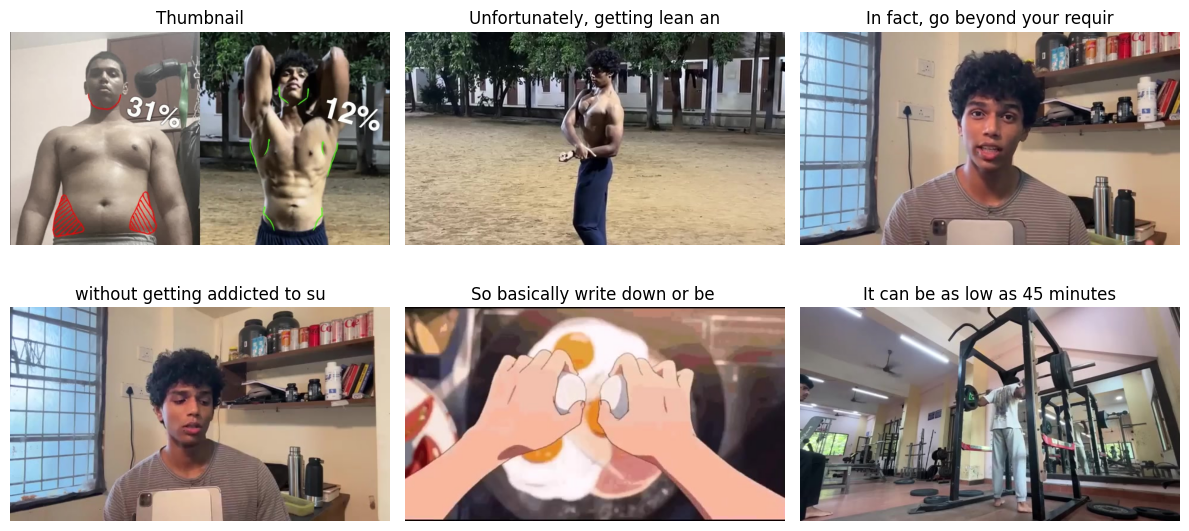

{'meta': {'video_id': 'iDzlbA3xIJ8',
  'title': 'Unfortunately… Getting Lean and looking Good Is This Simple',
  'duration_seconds': 316,
  'upload_date': '20251201',
  'channel_id': 'UCOHJjMVzonXj8G33I0wVk3g',
  'channel_name': 'Keerthi ',
  'category': ['People & Blogs'],
  'tags': [],
  'view_count': 247025,
  'like_count': 9283,
  'language': 'en',
  'thumbnail_url': 'https://i.ytimg.com/vi/iDzlbA3xIJ8/maxresdefault.jpg'},
 'thumbnail': '/content/drive/MyDrive/thumbnail_project/raw/iDzlbA3xIJ8/thumbnail.jpg',
 'frames': ['/content/drive/MyDrive/thumbnail_project/raw/iDzlbA3xIJ8/frames/frame_00002.jpg',
  '/content/drive/MyDrive/thumbnail_project/raw/iDzlbA3xIJ8/frames/frame_00218.jpg',
  '/content/drive/MyDrive/thumbnail_project/raw/iDzlbA3xIJ8/frames/frame_00198.jpg',
  '/content/drive/MyDrive/thumbnail_project/raw/iDzlbA3xIJ8/frames/frame_00088.jpg',
  '/content/drive/MyDrive/thumbnail_project/raw/iDzlbA3xIJ8/frames/frame_00281.jpg'],
 'texts': ['Unfortunately, getting lean and l

In [29]:
def load_video_sample(video_id, num_frames=5, show=True):
    folder = os.path.join(RAW_DIR, video_id)

    meta_path = os.path.join(folder, "meta.json")
    meta = {}
    if os.path.exists(meta_path):
        with open(meta_path) as f:
            meta = json.load(f)

    thumb_path = os.path.join(folder, "thumbnail.jpg")

    aligned_path = os.path.join(folder, "aligned_pairs.json")
    pairs = []
    if os.path.exists(aligned_path):
        with open(aligned_path) as f:
            pairs = json.load(f)

    # filter pairs text
    pairs = [p for p in pairs if p.get("transcript_text", "").strip() != ""]

    # random samples
    sampled_pairs = random.sample(pairs, min(num_frames, len(pairs)))

    frames = []
    texts = []

    for p in sampled_pairs:
        frame_path = os.path.join(folder, "frames", p["frame_file"])
        if os.path.exists(frame_path):
            frames.append(frame_path)
            texts.append(p["transcript_text"])

    if show:
        plt.figure(figsize=(12, 6))

        # thumbnail
        if os.path.exists(thumb_path):
            plt.subplot(2, 3, 1)
            plt.imshow(Image.open(thumb_path))
            plt.title("Thumbnail")
            plt.axis("off")

        # frames + text
        for i, (frame, text) in enumerate(zip(frames, texts)):
            plt.subplot(2, 3, i+2)
            plt.imshow(Image.open(frame))
            plt.title(text[:30])
            plt.axis("off")

        plt.tight_layout()
        plt.show()

    return {
        "meta": meta,
        "thumbnail": thumb_path,
        "frames": frames,
        "texts": texts
    }
sample = load_video_sample("iDzlbA3xIJ8", 5)
sample

In [ ]:
# import shutil
# shutil.make_archive("raw_backup", "zip", "raw")

'/content/raw_backup.zip'